In [ ]:
%pip install qiskit qiskit-algorithms qiskit-aer qiskit-ibm-runtime matplotlib scipy ipywidgets pylatexenc

In [ ]:

from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=getpass("Paste your IBM Quantum API key: "), # note that this is a box that you have to paste the key into
    set_as_default=True,
    overwrite=True,
)

import numpy as np
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit_algorithms import TrotterQRTE
from qiskit.primitives import StatevectorEstimator


Paste your IBM Quantum API key: ··········


We built an interactive four-spin Ising simulation to explore the tradeoff between Trotter approximation accuracy and circuit cost. We compare first- and second-order formulas, introduce simulated CNOT noise, and test zero-noise extrapolation on neighboring-spin correlations.
---



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.linalg import expm
from qiskit import transpile
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_algorithms import TimeEvolutionProblem, TrotterQRTE

In [ ]:
from math import sin, cos

def get_hamiltonian(L, J, h, alpha=0):
    ZZ_tuples = [
        ("ZZ", [i, i + 1], -J)
        for i in range(L - 1)
    ]

    Z_tuples = [
        ("Z", [i], -h * sin(alpha))
        for i in range(L)
    ]

    X_tuples = [
        ("X", [i], -h * cos(alpha))
        for i in range(L)
    ]

    hamiltonian = SparsePauliOp.from_sparse_list(
        [*ZZ_tuples, *Z_tuples, *X_tuples],
        num_qubits=L
    )

    return hamiltonian.simplify()

In [ ]:
# Four spins, with the middle two initially set to 1.
H = get_hamiltonian(L=4, J=0.2, h=1.0, alpha=0)
initial_state = Statevector.from_label("0110")
final_time = 1.6

problem = TimeEvolutionProblem(
    H,
    initial_state=initial_state,
    time=final_time
)

print("Four-qubit experiment ready.")

Four-qubit experiment ready.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.linalg import expm
from qiskit import transpile

## Experiment: accuracy versus circuit cost

We simulate four interacting spins starting in |0110⟩.

We compare first-order and second-order Trotter formulas against
exact evolution, measuring spin correlations and final-state infidelity.

At four steps:
- First order: infidelity 0.0009997409, 28 CNOTs.
- Second order: infidelity 0.0001134937, 52 CNOTs.

Second order improves full-state accuracy, while the measured
neighboring-spin correlations are nearly identical.

Next question: does this advantage survive simulated gate noise?

In [ ]:
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

L = H.num_qubits

correlation_op = SparsePauliOp.from_sparse_list(
    [("ZZ", [i, i + 1], 1.0) for i in range(L - 1)],
    num_qubits=L
) / (L - 1)

starting_state = Statevector(problem.initial_state)
time_limit = problem.time
H_matrix = H.to_matrix()


def exact_correlation(time):
    state = starting_state.evolve(expm(-1j * time * H_matrix))
    return float(state.expectation_value(correlation_op).real)


# Smooth reference curve, calculated once.
exact_times = np.linspace(0, time_limit, 101)
exact_values = [exact_correlation(t) for t in exact_times]


def compare_formulas(steps):
    dt = time_limit / steps
    times = np.linspace(0, time_limit, steps + 1)

    # Reference values at the actual Trotter-step boundaries.
    reference = np.array([exact_correlation(t) for t in times])

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(exact_times, exact_values, "k-", label="Exact reference")

    rows = []

    methods = [
        ("First order", LieTrotter(), "royalblue", "o"),
        ("Second order", SuzukiTrotter(order=2), "darkorange", "s")
    ]

    for name, formula, color, marker in methods:
        step_circuit = PauliEvolutionGate(
            H, time=dt, synthesis=formula
        ).definition

        state = starting_state
        values = [float(state.expectation_value(correlation_op).real)]
        full_circuit = problem.initial_state.copy()

        for _ in range(steps):
            state = state.evolve(step_circuit)
            values.append(
                float(state.expectation_value(correlation_op).real)
            )
            full_circuit.compose(step_circuit, inplace=True)

        # Use the same basic gates and compilation settings.
        compiled = transpile(
            full_circuit,
            basis_gates=["rx", "ry", "rz", "cx"],
            optimization_level=0
        )

        max_error = np.max(np.abs(np.array(values) - reference))

        rows.append((
            name,
            max_error,
            compiled.depth(),
            compiled.count_ops().get("cx", 0)
        ))

        ax.plot(
            times, values,
            linestyle="--", marker=marker,
            color=color, label=name
        )

    ax.set_xlabel("Simulated time")
    ax.set_ylabel("Average neighboring ZZ correlation")
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(f"Product-formula comparison: {steps} steps")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print(f"Time per step: {dt:.3f}\n")
    print(f"{'Method':<15} {'Max corr. error':>16} {'Depth':>8} {'CNOTs':>8}")

    for name, error, depth, cnots in rows:
        print(f"{name:<15} {error:>16.6f} {depth:>8} {cnots:>8}")


widgets.interact(
    compare_formulas,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=40,
        description="Steps:",
        continuous_update=False
    )
);

interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=40, min=1), Output…

In [ ]:
exact_final = starting_state.evolve(
    expm(-1j * time_limit * H_matrix)
)

for name, formula in [
    ("First order", LieTrotter()),
    ("Second order", SuzukiTrotter(order=2))
]:
    solver = TrotterQRTE(formula, num_timesteps=4)
    result_check = solver.evolve(problem)

    circuit_check = transpile(
        result_check.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    final_check = Statevector(circuit_check)

    fidelity = abs(
        np.vdot(exact_final.data, final_check.data)
    ) ** 2

    print(f"{name}: state infidelity = {max(0, 1-fidelity):.10f}")

First order: state infidelity = 0.0009997409
Second order: state infidelity = 0.0001134937


In [ ]:
from scipy.linalg import expm

exact_operator = expm(-1j * final_time * H.to_matrix())
exact_state = initial_state.evolve(exact_operator)

for state, probability in exact_state.probabilities_dict().items():
    print(f"{state}: {probability:.4%}")

0000: 0.0017%
0001: 0.1285%
0010: 0.0004%
0011: 0.0691%
0100: 0.0004%
0101: 2.2469%
0110: 0.0634%
0111: 0.0545%
1000: 0.1285%
1001: 92.2067%
1010: 2.2469%
1011: 0.2719%
1100: 0.0691%
1101: 0.2719%
1110: 0.0545%
1111: 2.1857%


In [ ]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit.quantum_info import state_fidelity

# Apply simulated noise after every CNOT.
noise_strength = 0.01

noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(
    depolarizing_error(noise_strength, 2),
    ["cx"]
)

simulator = AerSimulator(
    method="density_matrix",
    noise_model=noise_model
)

exact_final = starting_state.evolve(
    expm(-1j * time_limit * H_matrix)
)

print("Four Trotter steps; lower infidelity is better.\n")

for name, formula in [
    ("First order", LieTrotter()),
    ("Second order", SuzukiTrotter(order=2))
]:
    solver = TrotterQRTE(formula, num_timesteps=4)
    evolution = solver.evolve(problem)

    circuit = transpile(
        evolution.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    # Calculate this circuit's state without noise.
    ideal_state = Statevector(circuit)
    ideal_error = 1 - state_fidelity(exact_final, ideal_state)

    # Calculate its state with simulated noise.
    noisy_circuit = circuit.copy()
    noisy_circuit.save_density_matrix()

    output = simulator.run(noisy_circuit, shots=1).result()
    noisy_state = output.data(0)["density_matrix"]
    noisy_error = 1 - state_fidelity(exact_final, noisy_state)

    print(name)
    print(f"  CNOTs: {circuit.count_ops().get('cx', 0)}")
    print(f"  Noise-free infidelity: {ideal_error:.8f}")
    print(f"  Noisy infidelity:      {noisy_error:.8f}")
    print()

Four Trotter steps; lower infidelity is better.

First order
  CNOTs: 28
  Noise-free infidelity: 0.00099974
  Noisy infidelity:      0.18911367

Second order
  CNOTs: 52
  Noise-free infidelity: 0.00011349
  Noisy infidelity:      0.31787304



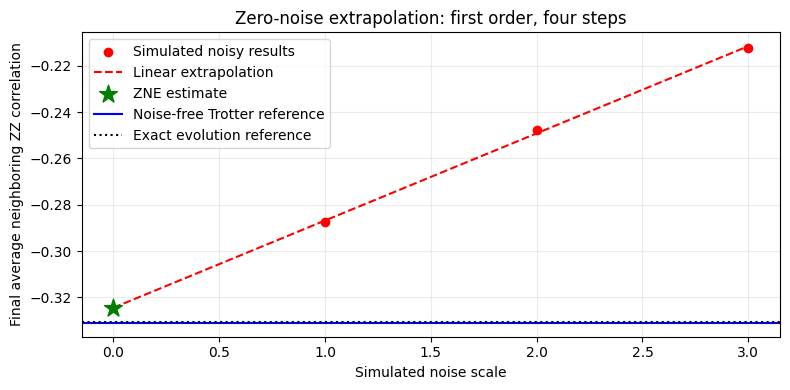

Baseline noisy correlation: -0.28750877
ZNE estimate:               -0.32446117
Noise-free Trotter:         -0.33100917
Exact evolution:           -0.33076557

Absolute error against noise-free Trotter:
Before mitigation: 0.04350040
After mitigation:  0.00654800


In [ ]:
# Build one fixed circuit for the mitigation experiment.
zne_solver = TrotterQRTE(LieTrotter(), num_timesteps=4)
zne_evolution = zne_solver.evolve(problem)

zne_circuit = transpile(
    zne_evolution.evolved_state,
    basis_gates=["rx", "ry", "rz", "cx"],
    optimization_level=0
)

base_noise = 0.01


def correlation_with_noise(scale):
    # Scale the depolarizing channel.
    # Scale 0 means no noise; scale 1 is our baseline.
    strength = 1 - (1 - base_noise) ** scale

    model = NoiseModel()
    model.add_all_qubit_quantum_error(
        depolarizing_error(strength, 2),
        ["cx"]
    )

    backend = AerSimulator(
        method="density_matrix",
        noise_model=model
    )

    experiment = zne_circuit.copy()
    experiment.save_density_matrix()

    output = backend.run(experiment, shots=1).result()
    density_matrix = output.data(0)["density_matrix"]

    return float(
        density_matrix.expectation_value(correlation_op).real
    )


# These are the noisy results used for extrapolation.
noise_scales = np.array([1.0, 2.0, 3.0])
noisy_values = np.array([
    correlation_with_noise(scale) for scale in noise_scales
])

# Fit a straight line using ONLY the noisy results.
fit = np.polyfit(noise_scales, noisy_values, deg=1)
mitigated_value = float(np.polyval(fit, 0))

# References used for evaluation, not for fitting.
noise_free_value = float(
    Statevector(zne_circuit).expectation_value(correlation_op).real
)

exact_final_state = Statevector(problem.initial_state).evolve(
    expm(-1j * problem.time * problem.hamiltonian.to_matrix())
)
exact_value = float(
    exact_final_state.expectation_value(correlation_op).real
)

# Display the experiment.
plot_scales = np.linspace(0, 3, 100)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    noise_scales, noisy_values,
    color="red", label="Simulated noisy results", zorder=3
)
ax.plot(
    plot_scales, np.polyval(fit, plot_scales),
    "--", color="red", label="Linear extrapolation"
)
ax.scatter(
    [0], [mitigated_value],
    color="green", marker="*", s=180,
    label="ZNE estimate", zorder=4
)
ax.axhline(
    noise_free_value, color="blue",
    label="Noise-free Trotter reference"
)
ax.axhline(
    exact_value, color="black", linestyle=":",
    label="Exact evolution reference"
)
ax.set_xlabel("Simulated noise scale")
ax.set_ylabel("Final average neighboring ZZ correlation")
ax.set_title("Zero-noise extrapolation: first order, four steps")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Baseline noisy correlation: {noisy_values[0]:.8f}")
print(f"ZNE estimate:               {mitigated_value:.8f}")
print(f"Noise-free Trotter:         {noise_free_value:.8f}")
print(f"Exact evolution:           {exact_value:.8f}")

print("\nAbsolute error against noise-free Trotter:")
print(f"Before mitigation: {abs(noisy_values[0] - noise_free_value):.8f}")
print(f"After mitigation:  {abs(mitigated_value - noise_free_value):.8f}")

In [ ]:
def interactive_mitigation(steps):
    # Keep the physical problem fixed; change only Trotter steps.
    solver = TrotterQRTE(LieTrotter(), num_timesteps=steps)
    evolution = solver.evolve(problem)

    circuit = transpile(
        evolution.evolved_state,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    ideal = Statevector(circuit)
    ideal_corr = float(
        ideal.expectation_value(correlation_op).real
    )

    exact = Statevector(problem.initial_state).evolve(
        expm(-1j * problem.time * problem.hamiltonian.to_matrix())
    )
    exact_corr = float(
        exact.expectation_value(correlation_op).real
    )

    # Run this circuit at three simulated noise strengths.
    scales = np.array([1.0, 2.0, 3.0])
    values = []

    for scale in scales:
        strength = 1 - (1 - 0.01) ** scale

        model = NoiseModel()
        model.add_all_qubit_quantum_error(
            depolarizing_error(strength, 2), ["cx"]
        )

        backend = AerSimulator(
            method="density_matrix",
            noise_model=model
        )

        experiment = circuit.copy()
        experiment.save_density_matrix()

        output = backend.run(experiment, shots=1).result()
        rho = output.data(0)["density_matrix"]
        values.append(
            float(rho.expectation_value(correlation_op).real)
        )

    fit = np.polyfit(scales, values, deg=1)
    mitigated = float(np.polyval(fit, 0))

    x = np.linspace(0, 3, 100)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(scales, values, color="red", label="Noisy results")
    ax.plot(
        x, np.polyval(fit, x),
        "r--", label="Linear extrapolation"
    )
    ax.scatter(
        [0], [mitigated], color="green",
        marker="*", s=180, label="ZNE estimate", zorder=4
    )
    ax.axhline(
        ideal_corr, color="blue",
        label="Noise-free Trotter"
    )
    ax.axhline(
        exact_corr, color="black",
        linestyle=":", label="Exact evolution"
    )
    ax.set_xlabel("Simulated noise scale")
    ax.set_ylabel("Final average neighboring ZZ correlation")
    ax.set_title(f"First-order Trotter + ZNE: {steps} steps")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    before = abs(values[0] - ideal_corr)
    after = abs(mitigated - ideal_corr)

    print(f"Steps: {steps} | Depth: {circuit.depth()}")
    print(f"CNOTs per circuit: {circuit.count_ops().get('cx', 0)}")
    print("ZNE uses three noisy circuit evaluations.\n")

    print("Absolute error against noise-free Trotter:")
    print(f"  Before mitigation: {before:.8f}")
    print(f"  After mitigation:  {after:.8f}")

    print("\nAbsolute error against exact evolution:")
    print(f"  Before mitigation: {abs(values[0] - exact_corr):.8f}")
    print(f"  After mitigation:  {abs(mitigated - exact_corr):.8f}")

    if before > 1e-12:
        reduction = 100 * (before - after) / before
        print(f"\nNoise-error reduction: {reduction:.1f}%")
        print("(A negative reduction means mitigation made it worse.)")


widgets.interact(
    interactive_mitigation,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=20,
        description="Steps:",
        continuous_update=False
    )
);

interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=20, min=1), Output…

In [ ]:
from functools import lru_cache

# Freeze this dashboard's settings.
dashboard_H = problem.hamiltonian
dashboard_initial = Statevector(problem.initial_state)
dashboard_time = problem.time
dashboard_observable = correlation_op
dashboard_noise = 0.01

dashboard_matrix = dashboard_H.to_matrix()


def reference_correlation(time):
    state = dashboard_initial.evolve(
        expm(-1j * time * dashboard_matrix)
    )
    return float(
        state.expectation_value(dashboard_observable).real
    )


reference_times = np.linspace(0, dashboard_time, 101)
reference_curve = [
    reference_correlation(t) for t in reference_times
]
reference_final = reference_correlation(dashboard_time)


@lru_cache(maxsize=20)
def dashboard_experiment(steps):
    dt = dashboard_time / steps

    step_circuit = PauliEvolutionGate(
        dashboard_H,
        time=dt,
        synthesis=LieTrotter()
    ).definition

    state = dashboard_initial
    correlations = [
        float(state.expectation_value(dashboard_observable).real)
    ]

    full_circuit = problem.initial_state.copy()

    for _ in range(steps):
        state = state.evolve(step_circuit)
        correlations.append(
            float(state.expectation_value(dashboard_observable).real)
        )
        full_circuit.compose(step_circuit, inplace=True)

    circuit = transpile(
        full_circuit,
        basis_gates=["rx", "ry", "rz", "cx"],
        optimization_level=0
    )

    ideal_corr = float(
        Statevector(circuit).expectation_value(
            dashboard_observable
        ).real
    )

    noisy_values = []

    for scale in [1, 2, 3]:
        strength = 1 - (1 - dashboard_noise) ** scale

        model = NoiseModel()
        model.add_all_qubit_quantum_error(
            depolarizing_error(strength, 2), ["cx"]
        )

        backend = AerSimulator(
            method="density_matrix",
            noise_model=model
        )

        experiment = circuit.copy()
        experiment.save_density_matrix()

        result_data = backend.run(
            experiment, shots=1
        ).result().data(0)

        rho = result_data["density_matrix"]
        noisy_values.append(
            float(rho.expectation_value(dashboard_observable).real)
        )

    fit = np.polyfit([1, 2, 3], noisy_values, deg=1)
    mitigated_corr = float(np.polyval(fit, 0))

    return {
        "correlations": correlations,
        "ideal_error": abs(ideal_corr - reference_final),
        "noisy_error": abs(noisy_values[0] - reference_final),
        "mitigated_error": abs(mitigated_corr - reference_final),
        "depth": circuit.depth(),
        "cnots": circuit.count_ops().get("cx", 0)
    }


# Calculate once so the slider can reuse the results.
print("Calculating 20 settings. Wait for the dashboard to appear…")
for step_count in range(1, 21):
    dashboard_experiment(step_count)


def show_dashboard(steps):
    selected = dashboard_experiment(steps)
    step_counts = np.arange(1, 21)
    records = [dashboard_experiment(int(n)) for n in step_counts]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    # Left: time evolution, without hardware noise.
    axes[0].plot(
        reference_times, reference_curve,
        color="black", label="Exact evolution"
    )
    axes[0].plot(
        np.linspace(0, dashboard_time, steps + 1),
        selected["correlations"],
        "o--", color="royalblue", label="Noise-free Trotter"
    )
    axes[0].set_xlabel("Simulated time")
    axes[0].set_ylabel("Average neighboring ZZ correlation")
    axes[0].set_ylim(-1.05, 1.05)
    axes[0].set_title(f"Spin evolution: {steps} steps")

    # Right: final observable error against exact evolution.
    for key, label, color in [
        ("ideal_error", "Without noise", "royalblue"),
        ("noisy_error", "With noise", "red"),
        ("mitigated_error", "With noise + ZNE", "green")
    ]:
        errors = [record[key] for record in records]
        axes[1].plot(
            step_counts, errors, ".-", color=color, label=label
        )
        axes[1].scatter(
            [steps], [selected[key]],
            color=color, s=70, zorder=4
        )

    axes[1].axvline(steps, color="gray", linestyle=":")
    axes[1].set_xlabel("Number of Trotter steps")
    axes[1].set_ylabel("Absolute final correlation error")
    axes[1].set_title("Accuracy versus step count")

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()

    plt.tight_layout()
    plt.show()

    print(
        f"First order | {steps} steps | "
        f"Depth: {selected['depth']} | "
        f"CNOTs per circuit: {selected['cnots']}"
    )
    print(f"Noise-free error: {selected['ideal_error']:.8f}")
    print(f"Noisy error:      {selected['noisy_error']:.8f}")
    print(f"ZNE error:        {selected['mitigated_error']:.8f}")
    print("\nAll errors above compare with exact evolution.")
    print("ZNE uses three noisy evaluations at scales 1, 2, and 3.")
    print("Synthetic CNOT noise; no hardware runs or shot sampling.")


widgets.interact(
    show_dashboard,
    steps=widgets.IntSlider(
        value=4,
        min=1,
        max=20,
        description="Steps:",
        continuous_update=False
    )
);

Calculating 20 settings. Wait for the dashboard to appear…


interactive(children=(IntSlider(value=4, continuous_update=False, description='Steps:', max=20, min=1), Output…

Real quantum hardware validation.

In [ ]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

hardware_service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=getpass("Paste your IBM API key: ").strip(),
    instance=input("Paste your instance CRN: ").strip()
)

hardware_backend = hardware_service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=4
)

print("Selected processor:", hardware_backend.name)

Paste your IBM API key: ··········
Paste your instance CRN: crn:v1:bluemix:public:quantum-computing:us-east:a/5e18c23b7cd94da8b2e98c7b85a2eea5:0b993757-d308-4219-bea4-20798bd8c03c::


qiskit_runtime_service._discover_account:WARNING:2026-11-15 00:07:11,369: Loading account with the given token. A saved account will not be used.


InvalidAccountError: 'Unable to retrieve instances. Please check that you are using a valid API token.'

In [ ]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

assert problem.hamiltonian.num_qubits == 4, "Expected four qubits."

# Same first-order, four-step experiment as our simulation.
hardware_evolution = TrotterQRTE(
    LieTrotter(), num_timesteps=4
).evolve(problem)

hardware_circuit = hardware_evolution.evolved_state.copy()
hardware_circuit.measure_all()

# Translate the circuit into gates supported by this processor.
pass_manager = generate_preset_pass_manager(
    backend=hardware_backend,
    optimization_level=1,
    seed_transpiler=42
)

hardware_isa = pass_manager.run(hardware_circuit)

print("Processor:", hardware_backend.name)
print("Compiled depth:", hardware_isa.depth())
print("Two-qubit gates:", hardware_isa.num_nonlocal_gates())
print("Planned shots: 1024")
print("Prepared only — no hardware job submitted yet.")

In [ ]:
from qiskit.transpiler.preset_passmanagers import (
    generate_preset_pass_manager
)

In [ ]:
from qiskit_ibm_runtime import SamplerV2

# Guard against accidentally submitting again in this runtime.
if "hardware_job" not in globals():
    hardware_sampler = SamplerV2(
        mode=hardware_backend,
        options={"max_execution_time": 60}
    )

    hardware_job = hardware_sampler.run(
        [hardware_isa],
        shots=1024
    )

print("Job ID:", hardware_job.job_id())
print("Status:", hardware_job.status())

Job ID: dbsf35mjjaos73ak442g

In [ ]:
print(hardware_job.status())

In [ ]:
hardware_result = hardware_job.result()
hardware_counts = hardware_result[0].data.meas.get_counts()

# Each outcome is ordered q3 q2 q1 q0.
# Matching neighbors contribute +1; different neighbors contribute -1.
def correlation_from_bitstring(bits):
    bits = bits.replace(" ", "")
    pair_values = [
        1 if bits[i] == bits[i + 1] else -1
        for i in range(len(bits) - 1)
    ]
    return sum(pair_values) / len(pair_values)

total_shots = sum(hardware_counts.values())

hardware_correlation = sum(
    count * correlation_from_bitstring(bits)
    for bits, count in hardware_counts.items()
) / total_shots

print("Measured shots:", total_shots)
print(f"Hardware correlation: {hardware_correlation:.8f}")
print("Measurement counts:", hardware_counts)

In [ ]:
# Calculate uncertainty using each shot's average pair correlation.
N = total_shots

squared_sum = sum(
    count * correlation_from_bitstring(bits) ** 2
    for bits, count in hardware_counts.items()
)

sample_variance = max(
    0.0,
    (squared_sum - N * hardware_correlation**2) / (N - 1)
)
standard_error = np.sqrt(sample_variance / N)

# Recalculate the references for this hardware experiment.
reference_state = Statevector(problem.initial_state).evolve(
    expm(-1j * problem.time * problem.hamiltonian.to_matrix())
)
exact_corr = float(
    reference_state.expectation_value(correlation_op).real
)
trotter_corr = float(
    Statevector(hardware_circuit.remove_final_measurements(inplace=False))
    .expectation_value(correlation_op).real
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(exact_corr, color="black", label="Exact evolution")
ax.axhline(
    trotter_corr, color="royalblue", linestyle="--",
    label="Noise-free Trotter"
)
ax.errorbar(
    [0], [hardware_correlation],
    yerr=[1.96 * standard_error],
    fmt="o", color="purple", capsize=6,
    label="Hardware: approximate 95% sampling interval"
)
ax.set_xticks([0])
ax.set_xticklabels(["ibm_marrakesh · 1,024 shots"])
ax.set_ylabel("Average neighboring ZZ correlation")
ax.set_title("Hardware validation: first order, four steps")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Hardware correlation: {hardware_correlation:.5f}")
print(f"Sampling standard error: {standard_error:.5f}")
print("The interval describes shot uncertainty, not hardware bias.")